# Week 10 Demo: Unsupervised Learning on the Palmer Penguins

A compact tour of this week's ideas (Chapter 9) on a **new, real dataset** — no synthetic blobs, no figure-saving boilerplate, just the concepts that matter:

1. **Why scaling matters** for distance-based clustering
2. **K-Means** and choosing `k` with **inertia (elbow)** and the **silhouette score**
3. **Clusters vs. ground truth** (adjusted Rand index) — and why the "best" `k` need not match the number of classes
4. **Gaussian Mixtures**: soft, elliptical clusters + **anomaly detection**
5. **DBSCAN**: density-based clustering for outliers and non-convex shapes

## The dataset

> **Palmer Penguins** — 344 penguins of 3 species (Adelie, Gentoo, Chinstrap) measured on 4 body dimensions. It has the properties that make clustering *interesting*:
>
> - **Features on wildly different scales** — body mass is in the thousands of grams, bill depth is ~15-20 mm. Distance-based methods are dominated by the big-scale feature unless we standardize.
> - **Real missing values** — a few rows have blank measurements.
> - **Overlapping, elongated species clusters** — not neat round blobs, which separates the methods.
> - **Known species labels** — hidden from the algorithms, used only to *score* how well they recovered the structure.

It loads straight from OpenML through scikit-learn.

**Data source:** [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) (Gorman, Williams & Fraser, 2014), via `fetch_openml`.

### API References

| Tool | What it does here | Documentation |
|------|-------------------|---------------|
| `fetch_openml` | Download the penguins dataset | [datasets.fetch_openml](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_openml.html) |
| `StandardScaler` | Rescale features so distances are fair | [preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) |
| `KMeans` | Centroid-based clustering (`inertia_`, `labels_`) | [cluster.KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) |
| `silhouette_score` | Judge cluster separation to pick `k` | [metrics.silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) |
| `adjusted_rand_score` | Grade clusters against true labels | [metrics.adjusted_rand_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html) |
| `GaussianMixture` | Soft/elliptical clusters + density (`predict_proba`, `score_samples`) | [mixture.GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html) |
| `DBSCAN` | Density-based clustering, finds outliers & odd shapes | [cluster.DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html) |
| `make_moons` | Non-convex toy data to contrast the methods | [datasets.make_moons](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) |
| `pd.crosstab` | Count species per cluster to inspect matches | [pandas.crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html) |

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/pjmcswee/IST707-Notebooks/blob/main/week10/week10_unsupervised_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

RANDOM_STATE = 42

penguins = fetch_openml(name='penguins', version=1, as_frame=True, parser='auto').frame

features = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
data = penguins.dropna(subset=features).copy()   # drop the handful of rows missing measurements

X = data[features].to_numpy()
species = data['species'].astype('category')
y = species.cat.codes.to_numpy()                 # true labels: used ONLY for scoring

print(f'{len(data)} penguins, {X.shape[1]} features, {species.nunique()} species')
print(species.value_counts().to_string())
data[features].describe().loc[['min', 'max', 'mean', 'std']].round(1)

342 penguins, 4 features, 3 species
species
Adelie       151
Gentoo       123
Chinstrap     68


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
min,32.1,13.1,172.0,2700.0
max,59.6,21.5,231.0,6300.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0


Notice the scale gap in that table: `body_mass_g` spans thousands while `culmen_depth_mm` spans a handful. Clustering measures **distances** between penguins, so without rescaling, body mass alone decides who is "close" to whom.

**A couple of setup lines that weren't in the lecture:**
- `data.dropna(subset=features)` removes the handful of rows with blank measurements — scikit-learn's clustering can't handle `NaN`, so we drop those rows (only a few, so it's harmless here).
- `species.cat.codes` turns the species *names* ('Adelie', 'Gentoo', 'Chinstrap') into integer codes (0, 1, 2). We only build `y` so we can *score* the clustering later; the algorithms never see it.

## 1. Why scaling matters

We run K-Means with `k=3` twice — on the raw features and on standardized features — and score each against the true species.

### Two tools here that weren't in the lecture

**`StandardScaler`** rescales each feature to mean 0 and standard deviation 1, so a difference of "one gram of body mass" and "one millimeter of bill depth" count equally in a distance calculation. (You may have met it in earlier weeks; it did not appear in this chapter.)

**`adjusted_rand_score(labels_true, labels_pred)`** is how we *grade* a clustering against known labels. The problem it solves: cluster numbers are arbitrary — K-Means might call the Gentoos "cluster 2" while the true label is "0", so we can't just compare label numbers or compute accuracy. The Rand index instead looks at **every pair of penguins** and asks: did the clustering and the truth *agree* on whether that pair belongs together? The *adjusted* version corrects for agreements that would happen by random chance, giving:
- **1.0** — identical grouping (ignoring how clusters are numbered),
- **~0.0** — no better than random,
- **< 0** — worse than random.

It needs the true labels, so it only works when you have them (here, for evaluation). We'll use it throughout as our "how well did the clustering recover the real groups?" score.

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

X_scaled = StandardScaler().fit_transform(X)

for label, data_in in [('raw features', X), ('standardized', X_scaled)]:
    km = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(data_in)
    ari = adjusted_rand_score(y, km.labels_)
    print(f'K-Means on {label:13s}-> ARI vs species = {ari:.3f}')

K-Means on raw features -> ARI vs species = 0.314
K-Means on standardized -> ARI vs species = 0.793


Standardizing roughly **doubles** the agreement with the true species. On the raw data, `body_mass_g` dominates every distance and the other three measurements barely count; after scaling, all four features contribute, and the clusters line up with real biology. **Lesson:** for any distance-based method (K-Means, DBSCAN, k-NN), standardize first. We use `X_scaled` from here on.

## 2. Choosing k: the elbow and the silhouette

In a real problem you don't know the number of groups. **Inertia** (within-cluster squared distance) always falls as `k` rises — look for the *elbow*. The **silhouette score** (−1 to 1) measures how cleanly separated the clusters are and usually has a clear peak.

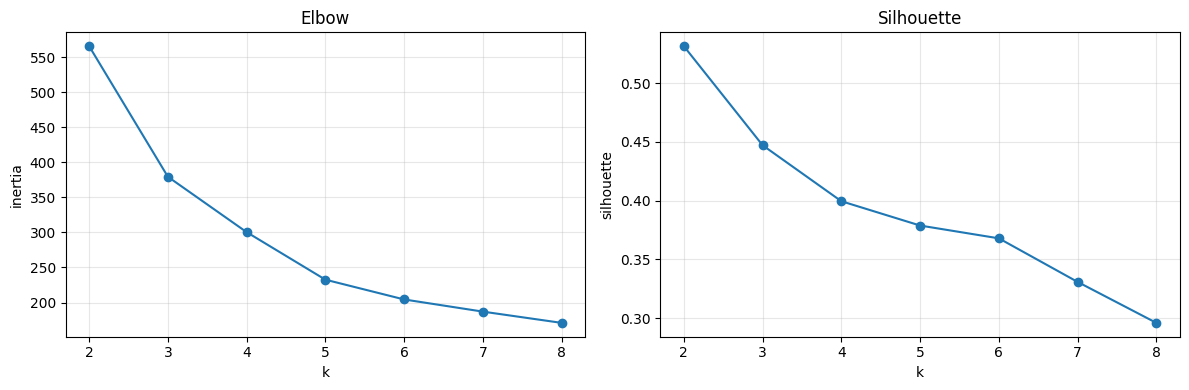

Silhouette is highest at k = 2 (score 0.532); there are really 3 species.


In [3]:
from sklearn.metrics import silhouette_score

ks = range(2, 9)
models = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled) for k in ks]
inertias = [m.inertia_ for m in models]
silhouettes = [silhouette_score(X_scaled, m.labels_) for m in models]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(list(ks), inertias, 'o-'); ax1.set_xlabel('k'); ax1.set_ylabel('inertia'); ax1.set_title('Elbow')
ax2.plot(list(ks), silhouettes, 'o-'); ax2.set_xlabel('k'); ax2.set_ylabel('silhouette'); ax2.set_title('Silhouette')
for ax in (ax1, ax2): ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

best_k = list(ks)[int(np.argmax(silhouettes))]
print(f'Silhouette is highest at k = {best_k} (score {max(silhouettes):.3f}); there are really 3 species.')

The silhouette prefers **k = 2**, even though there are **3** species. That isn't a bug — two of the species (Adelie and Chinstrap) overlap heavily in body measurements, so geometrically the data looks like two well-separated groups. **Lesson:** cluster-quality metrics reward clean separation, not agreement with human categories; the mathematically "best" `k` can differ from the true number of classes.

## 3. How well do 3 clusters match the species?

We force `k=3` (because we happen to know there are 3 species) and compare the clusters to the true labels. Beyond the single adjusted-Rand number, **`pd.crosstab(species, clusters)`** (a pandas helper, not from the lecture) builds a table counting how many penguins of each species fell into each cluster — a quick way to *see* which groups the algorithm merged or split.

In [4]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
print(f'Adjusted Rand index: {adjusted_rand_score(y, km3.labels_):.3f}\n')

crosstab = pd.crosstab(species.to_numpy(), km3.labels_,
                       rownames=['species'], colnames=['cluster'])
print(crosstab)

Adjusted Rand index: 0.793

cluster     0    1    2
species                
Adelie     24    0  127
Chinstrap  63    0    5
Gentoo      0  123    0


Gentoo (the most physically distinct species) lands almost entirely in one cluster, while Adelie and Chinstrap bleed into each other — exactly the overlap the silhouette score reacted to in step 2. The ARI (~0.8) confirms a strong but imperfect recovery of the species from body measurements alone, with no labels.

## 4. Gaussian Mixtures: soft clusters and anomaly detection

K-Means assigns every point to exactly one round cluster. A **Gaussian Mixture Model** fits `k` *elliptical* Gaussians and gives each penguin a **probability** of belonging to each — a better match for stretched, overlapping species. It also yields a **density** per point, so the least-likely penguins are natural anomalies.

In [5]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
print(f'GMM adjusted Rand index: {adjusted_rand_score(y, gm.predict(X_scaled)):.3f}')
print(f'(compare to K-Means at k=3: {adjusted_rand_score(y, km3.labels_):.3f})\n')

# Soft assignment: show how confident the model is for a few penguins.
proba = gm.predict_proba(X_scaled).round(2)
print('Membership probabilities for 5 penguins (one row per penguin):')
print(proba[:5])

GMM adjusted Rand index: 0.960
(compare to K-Means at k=3: 0.793)

Membership probabilities for 5 penguins (one row per penguin):
[[1.   0.   0.  ]
 [1.   0.   0.  ]
 [0.98 0.   0.02]
 [1.   0.   0.  ]
 [1.   0.   0.  ]]


The GMM's elliptical clusters match the elongated species shapes far better than K-Means' round ones, so its ARI is markedly higher. The probability rows show **soft** assignment: a penguin on the Adelie/Chinstrap boundary gets split confidence (e.g. 0.6 / 0.4) instead of being forced into one bin.

Next we reuse `gm.score_samples` from the lecture, which returns each point's **log-density** under the model. The slides picked a cutoff with `np.percentile` (e.g. flag the lowest 2%); below we instead just sort the densities with `np.argsort` and take the **5 lowest** — same idea (lowest density = most anomalous), simpler to read for a short list.

In [6]:
# Anomaly detection: the lowest-density penguins under the fitted model.
log_density = gm.score_samples(X_scaled)
n_anomalies = 5
anomaly_idx = np.argsort(log_density)[:n_anomalies]

report = data.iloc[anomaly_idx][['species'] + features].copy()
report['log_density'] = log_density[anomaly_idx].round(1)
print(f'{n_anomalies} most anomalous penguins (lowest density under the GMM):\n')
print(report.to_string(index=False))
print(f'\nTypical log-density is around {np.median(log_density):.1f}; '
      f'these sit far below it.')

5 most anomalous penguins (lowest density under the GMM):

  species  culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  log_density
Chinstrap              58.0             17.8              181.0       3700.0        -13.3
   Gentoo              44.4             17.3              219.0       5250.0         -9.7
   Gentoo              59.6             17.0              230.0       6050.0         -9.3
   Adelie              34.6             21.1              198.0       4400.0         -8.6
   Adelie              46.0             21.5              194.0       4200.0         -7.6

Typical log-density is around -3.1; these sit far below it.


These penguins carry unusual *combinations* of measurements (e.g. a body size that doesn't match the usual bill shape for that size). A density model flags them automatically: **low density = doesn't look like anything the model considers normal** — the same mechanism used for fraud and fault detection.

## 5. DBSCAN: outliers now, odd shapes next

**DBSCAN** groups points by *density* rather than distance to a center. It needs no `k`, labels low-density points as outliers (`-1`), and — unlike K-Means — can trace clusters of any shape. First, run it on the penguins to see the outlier flagging.

In [7]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.6, min_samples=5).fit(X_scaled)
n_clusters = len(set(db.labels_) - {-1})
n_outliers = int((db.labels_ == -1).sum())
print(f'DBSCAN found {n_clusters} dense clusters and flagged {n_outliers} penguins as outliers.')
print('(eps and min_samples control how dense a region must be to count as a cluster.)')

DBSCAN found 2 dense clusters and flagged 33 penguins as outliers.
(eps and min_samples control how dense a region must be to count as a cluster.)


### Where DBSCAN really shines: non-convex shapes

The penguin species are roughly blob-shaped, so K-Means and GMM do well there. DBSCAN's advantage appears when clusters are **not** round. The classic example is two interleaving crescents, which K-Means can only cut with a straight line.

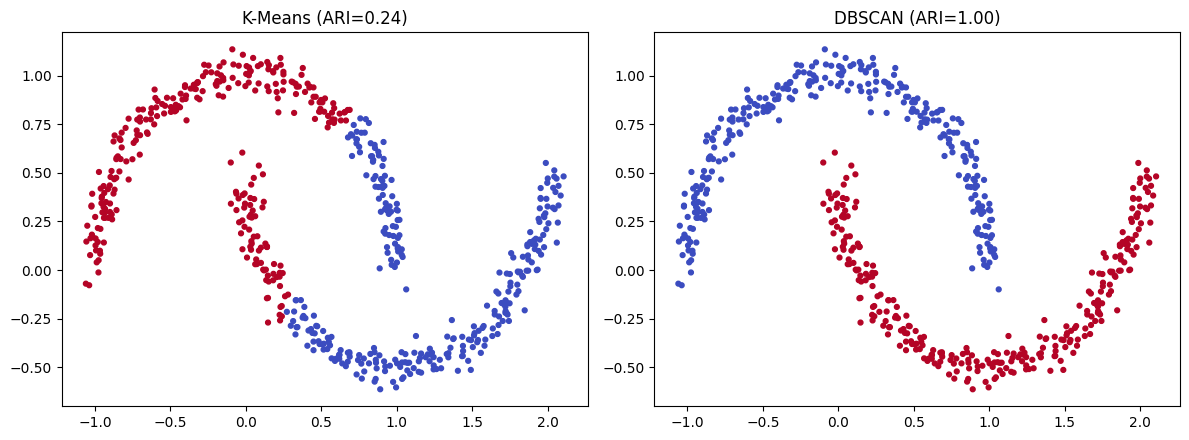

In [8]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=600, noise=0.05, random_state=RANDOM_STATE)

km_moons = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_moons)
db_moons = DBSCAN(eps=0.18, min_samples=5).fit(X_moons)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.scatter(X_moons[:, 0], X_moons[:, 1], c=km_moons.labels_, cmap='coolwarm', s=12)
ax1.set_title(f'K-Means (ARI={adjusted_rand_score(y_moons, km_moons.labels_):.2f})')
ax2.scatter(X_moons[:, 0], X_moons[:, 1], c=db_moons.labels_, cmap='coolwarm', s=12)
ax2.set_title(f'DBSCAN (ARI={adjusted_rand_score(y_moons, db_moons.labels_):.2f})')
plt.tight_layout(); plt.show()

K-Means splits the crescents with a straight boundary and gets about half of each wrong; DBSCAN follows the dense arcs and recovers both perfectly. **Lesson:** match the algorithm to the cluster shape — centroid methods assume round blobs; density methods handle anything connected.

## Takeaways

- **Standardize** before any distance-based clustering, or the largest-scale feature dominates (ARI ~0.3 -> ~0.8 on penguins).
- **Inertia + silhouette** help choose `k`, but the "best" `k` optimizes separation, not agreement with human labels — here the silhouette liked 2, not the true 3.
- **K-Means** is fast and simple but assumes round, equal-ish blobs. **Gaussian Mixtures** add elliptical shapes, soft probabilities, and a density score for anomalies (best ARI on penguins). **DBSCAN** needs no `k`, finds outliers, and handles arbitrary shapes, but is sensitive to `eps`/`min_samples`.
- Clustering is **unsupervised**: we validated against species only to check our work. In a real problem with no labels, you'd lean on internal metrics, stability, and domain interpretation instead.